
##Library Imports
Load every external tool the project needs before anything else runs.

In [1]:
# ═══════════════════════════════════════════════════════════════
#  ML-Based Water Quality Classification  |  23MCAJ301 | Group 7
#  TKM College of Engineering, Kollam
# ═══════════════════════════════════════════════════════════════

import pandas as pd                           # pandas  → load & manage tabular data (CSV → DataFrame)
import numpy as np                            # numpy   → fast numerical operations on arrays
import matplotlib.pyplot as plt              # matplotlib → base plotting library for all charts
import seaborn as sns                        # seaborn → higher-level plots built on matplotlib (heatmaps, box plots)

from sklearn.model_selection import StratifiedKFold
# StratifiedKFold → splits data into K folds while keeping the same class ratio in every fold
# Critical here because the Marginal class has only 121 samples; plain random splits could leave a test fold with very few

from sklearn.preprocessing import StandardScaler, LabelEncoder
# StandardScaler → scales each feature to mean=0, std=1  (x_new = (x − mean) / std)
#   ∙ Critical for SVM (distance-based) and good practice for all models
# LabelEncoder  → converts text labels (Excellent, Good, Fair, Marginal) → integers (0,1,2,3)

from sklearn.metrics import classification_report, confusion_matrix, f1_score
# classification_report → prints Precision, Recall, F1 per class + overall
# confusion_matrix      → table: actual class (rows) vs predicted class (cols)
# f1_score              → harmonic mean of Precision and Recall
#   ∙ We use average='macro' → equal weight to ALL classes regardless of sample size
#   ∙ DO NOT use accuracy → 99.0% of samples are Excellent/Good, so accuracy hides minority-class failure
#     (always predicting 'Excellent' already scores 54.6% accuracy; Excellent+Good vs rest is the real imbalance)

from imblearn.over_sampling import SMOTE
# SMOTE = Synthetic Minority Over-sampling Technique
# Generates new synthetic samples for minority classes (Fair, Marginal) by
# interpolating between real minority samples in 8-dimensional feature space
# Applied ONLY to training data — test data always stays real and imbalanced

# ── Extra imports used by the robustness checks added later ──────────────────
from sklearn.dummy import DummyClassifier                 # trivial baselines (majority class / stratified random guess)
from sklearn.utils.class_weight import compute_sample_weight  # per-sample weights for the class-weight baseline (used for Naive Bayes)
from sklearn.base import clone                             # copies a model's settings into a fresh, unfitted model
from sklearn.inspection import permutation_importance      # model-agnostic importance (also used in the feature-importance section)


## Load Dataset
Load the CSV and do a quick sanity check on shape, content, and class distribution.

In [2]:
# ── Load CSV into a pandas DataFrame ─────────────────────────────────────────
df = pd.read_csv('China_dataset.csv')        # reads CSV file → rows become records, columns become features
                                             # Dataset: Hou Bay, China | Karim et al. (2025)
# NOTE: 'CCME_Values' is the numeric WQI score the class label is derived from.
#       It must NEVER be used as a model input (it would leak the answer). Only the 8 features below are used.

# ── Quick sanity checks (every number below is COMPUTED from the data, not assumed) ──
print(df.shape)                              # (rows, columns): 14 columns = 8 features + target + CCME_Values + 4 metadata columns
print(df.head())                             # first 5 rows — confirm column names and data look correct

counts = df['CCME_WQI'].value_counts()       # count samples per WQI class
print(pd.concat([counts, (counts / len(df) * 100).round(1)], axis=1, keys=['count', 'percent']))
print(f"Excellent + Good share of all samples: {(counts['Excellent'] + counts['Good']) / len(df):.1%}")
# THIS IS THE IMBALANCE PROBLEM — Fair and Marginal together are only ~1% of the data

print(df.isnull().sum())                     # missing values per column
dates = pd.to_datetime(df['Date'], format='%d-%m-%Y')
print(f"Date range: {dates.min().date()} to {dates.max().date()}  ({dates.dt.year.nunique()} calendar years)")
print(f"Fully duplicated rows: {df.duplicated().sum()}")

# Observed CCME score range of each class in THIS dataset (do not assume textbook CCME bands)
print(df.groupby('CCME_WQI')['CCME_Values'].agg(['min', 'max']).round(2))


(45997, 14)
  Country     Area Waterbody Type        Date  Ammonia (mg/l)  \
0   China  Hou Bay            Bay  11-01-2001             3.5   
1   China  Hou Bay            Bay  12-02-2001             6.7   
2   China  Hou Bay            Bay  14-03-2001             4.5   
3   China  Hou Bay            Bay  17-04-2001             5.4   
4   China  Hou Bay            Bay  11-05-2001             3.3   

   Biochemical Oxygen Demand (mg/l)  Dissolved Oxygen (mg/l)  \
0                               0.7                 8.200000   
1                               2.1                11.684103   
2                               0.3                11.684103   
3                               5.2                11.684103   
4                               1.7                11.684103   

   Orthophosphate (mg/l)  pH (ph units)  Temperature (cel)  Nitrogen (mg/l)  \
0                   0.40            8.6               17.0             0.21   
1                   0.72            7.3               

##Exploratory Data Analysis (EDA)
Visualize class imbalance, feature correlations, and how each parameter differs across WQI classes.

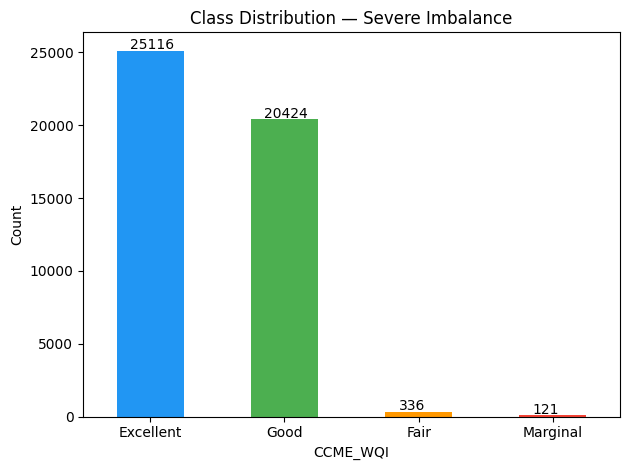

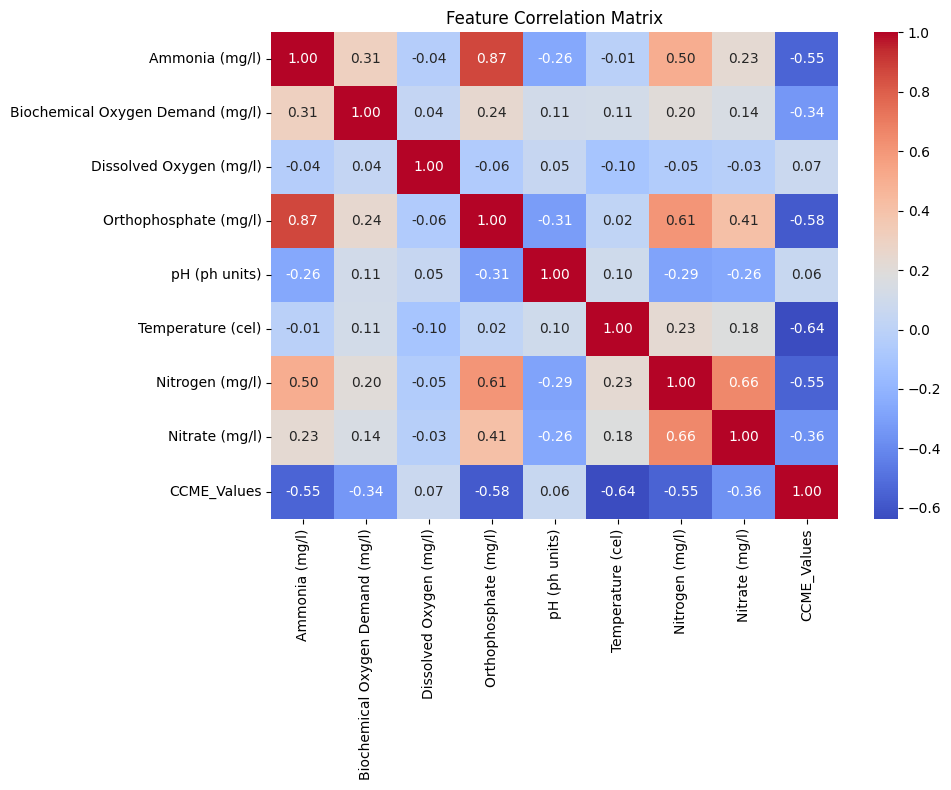

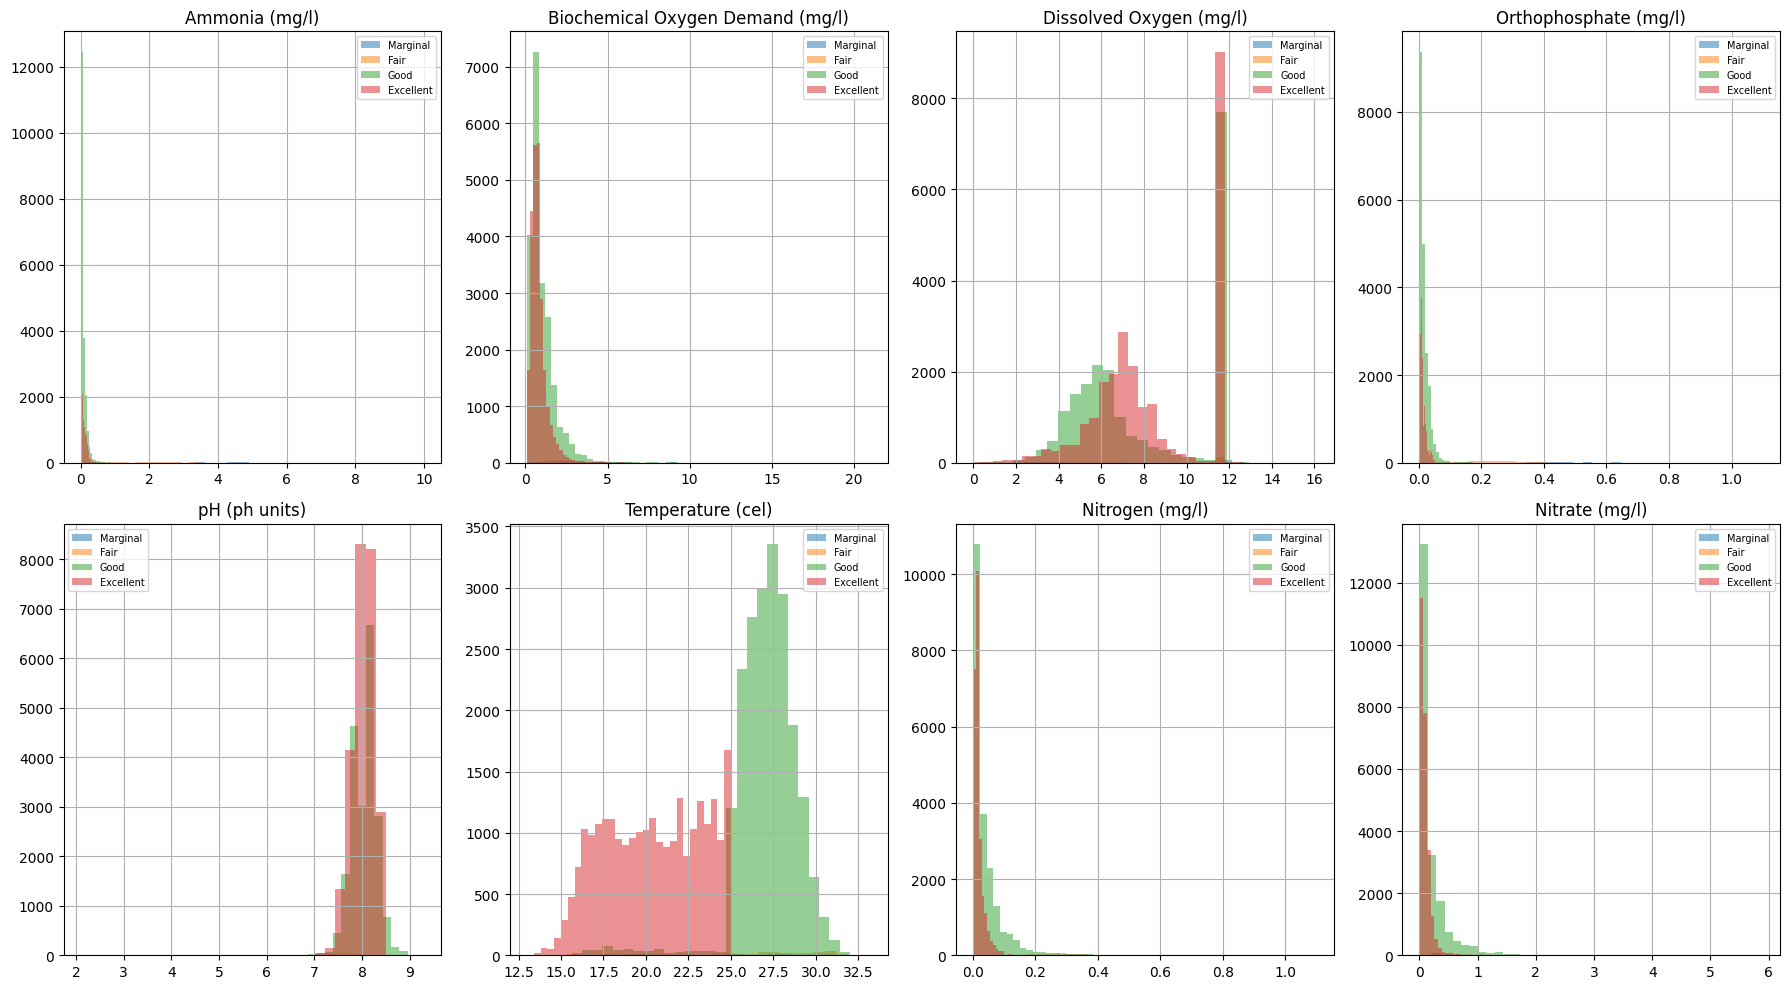

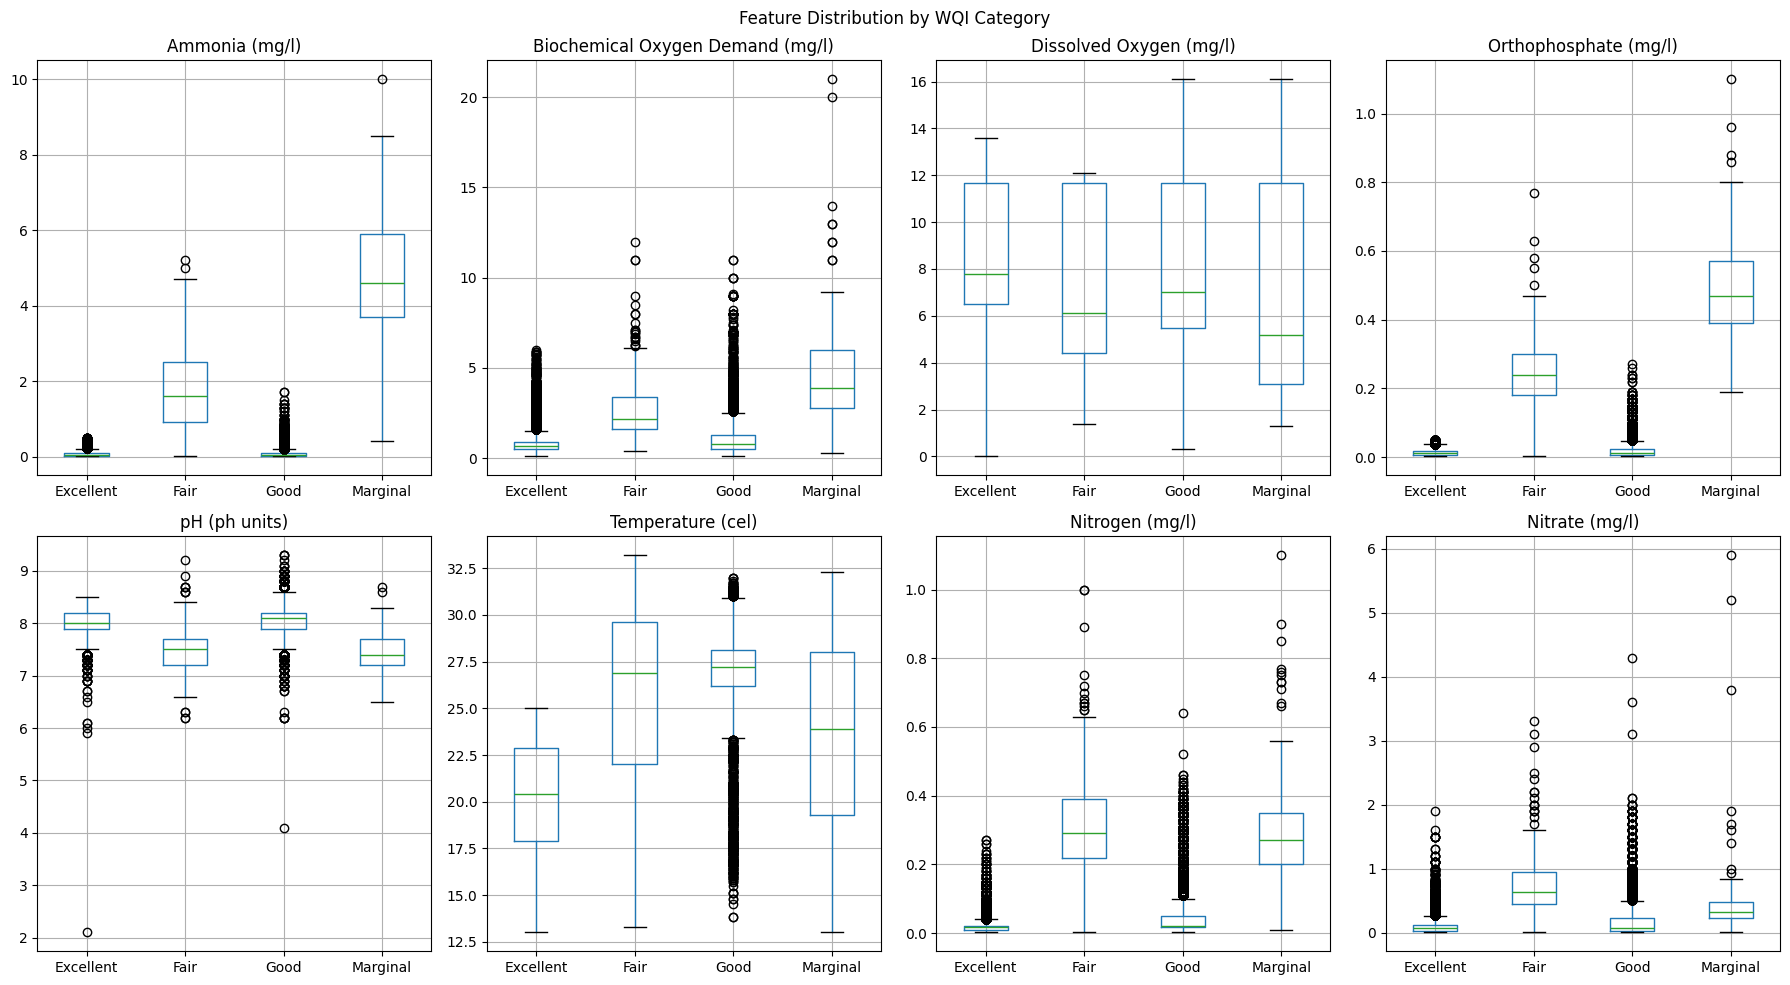

In [3]:
# ═══════════════════════════════════════════════════════════════
#  PLOT 1 — Class Distribution Bar Chart
#  Purpose: visualise the severe imbalance before modelling
# ═══════════════════════════════════════════════════════════════

ax = df['CCME_WQI'].value_counts().plot(     # count each class occurrence and pass to bar chart
    kind='bar',                              # bar chart type (not pie — bars show absolute counts clearly)
    color=['#2196F3', '#4CAF50', '#FF9800', '#F44336']
    # blue=Excellent, green=Good, orange=Fair, red=Marginal — intuitive traffic-light palette
)
plt.title('Class Distribution — Severe Imbalance')  # chart title describing the key finding
plt.ylabel('Count')                          # y-axis = number of samples per class
plt.xticks(rotation=0)                       # keep class names horizontal (not rotated 45°)

for p in ax.patches:                         # loop over every bar in the chart
    ax.annotate(
        f'{p.get_height()}',                 # text = exact sample count for that class
        (p.get_x() + 0.1, p.get_height() + 100)
        # position: 0.1 units right of bar's left edge, 100 units above bar top
    )

plt.tight_layout()                           # auto-adjust subplot padding to prevent label clipping
plt.savefig('class_distribution.png')        # save to PNG file in current directory
plt.show()                                   # render in notebook


# Define the 8 input feature column names — must match EXACTLY as they appear in the CSV
features = [
    'Ammonia (mg/l)',                        # nitrogen compound from agricultural/sewage runoff; toxic to aquatic life
    'Biochemical Oxygen Demand (mg/l)',      # oxygen bacteria need to decompose organic matter; high BOD → low DO
    'Dissolved Oxygen (mg/l)',               # oxygen available to fish; low values (roughly below 4-5 mg/L) stress or kill fish
    'Orthophosphate (mg/l)',                 # bioavailable phosphorus; triggers algal blooms → DO collapse
    'pH (ph units)',                         # acidity; healthy range 6.5–8.5; data also has extreme low outliers (check box plot: min ≈ 2.1)
    'Temperature (cel)',                     # warmer water holds less dissolved oxygen; seasonal cycles
    'Nitrogen (mg/l)',                       # total nitrogen (all forms); eutrophication driver alongside phosphorus
    'Nitrate (mg/l)'                         # oxidised nitrogen; WHO drinking limit 50 mg/L; blue-baby syndrome risk
]

# ═══════════════════════════════════════════════════════════════
#  PLOT 2 — Feature Correlation Heatmap
#  Purpose: check how correlated the 8 INPUT features are with each other
#  (matters for Naive Bayes, which assumes independence). Read the printed
#  coefficients below — do not assume which pairs are correlated.
# ═══════════════════════════════════════════════════════════════

plt.figure(figsize=(10, 8))                  # create a new 10×8 inch figure (prevents overlapping previous plot)

corr = df[features].corr()                   # Pearson correlation of the 8 input features ONLY
                                             # (the old version dropped just the label, so CCME_Values leaked into this heatmap)
                                             # -1 = perfect inverse relationship; +1 = perfect positive; 0 = no relationship
sns.heatmap(
    corr,
    annot=True,                              # print each correlation coefficient inside its cell
    cmap='coolwarm',                         # color map: deep blue = strong negative, deep red = strong positive
    fmt='.2f'                                # format numbers to 2 decimal places
)
plt.title('Feature Correlation Matrix (8 input features)')
plt.tight_layout()
plt.savefig('correlation.png')
plt.show()

# Data-driven readout of the heatmap (replaces the old hard-coded expectation)
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
strongest = upper.abs().idxmax()
print(f"Strongest feature pair: {strongest[0]} vs {strongest[1]}  (r = {upper[strongest]:.2f})")
print(f"Dissolved Oxygen vs BOD: r = {corr.loc['Dissolved Oxygen (mg/l)', 'Biochemical Oxygen Demand (mg/l)']:.2f}")
print(f"Ammonia vs Nitrate:      r = {corr.loc['Ammonia (mg/l)', 'Nitrate (mg/l)']:.2f}")


# ═══════════════════════════════════════════════════════════════
#  PLOTS 3 & 4 — Feature Distributions (Histogram + Box Plots)
#  Purpose: see how each physicochemical parameter differs per WQI class
# ═══════════════════════════════════════════════════════════════


# ── Plot 3 : Histograms ───────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 10))
# 2 rows × 4 columns of subplots; 18 inches wide × 10 inches tall

for i, feature in enumerate(features):      # iterate: i = 0..7, feature = column name
    ax = axes[i // 4, i % 4]               # select correct subplot: row = integer division, col = remainder
    for cat in df['CCME_WQI'].unique():      # for each WQI class (Excellent, Good, Fair, Marginal)
        df[df['CCME_WQI'] == cat][feature].hist(
            ax=ax,                           # draw on this subplot (not a new window)
            alpha=0.5,                       # 50% transparency so overlapping distributions are visible
            label=cat,                       # legend entry for this class
            bins=30                          # 30 equal-width bins across the feature's range
        )
    ax.set_title(feature)                    # subplot title = feature name
    ax.legend(fontsize=7)                    # show class legend in small font to fit

plt.tight_layout()
plt.savefig('feature_distributions.png')
plt.show()

# ── Plot 4 : Box Plots ────────────────────────────────────────────────────────
# Box plot shows median (line), IQR (box), whiskers (1.5×IQR), and outliers (dots)
fig, axes = plt.subplots(2, 4, figsize=(18, 10))

for i, feature in enumerate(features):
    ax = axes[i // 4, i % 4]
    df.boxplot(
        column=feature,                      # which feature to plot on the y-axis
        by='CCME_WQI',                       # group/split boxes by WQI class on x-axis
        ax=ax                                # draw on this subplot
    )
    ax.set_title(feature)                    # subplot title
    ax.set_xlabel('')                        # remove the auto-generated "Grouped by CCME_WQI" x-label (clutters the plot)

plt.suptitle('Feature Distribution by WQI Category')   # overall figure title
plt.tight_layout()
plt.savefig('boxplots.png')
plt.show()


##Encode Target + Define X, y + Setup KFold & Scaler
Convert text labels to integers and prepare the cross-validation objects used by all 4 classifiers.

In [4]:
# ── Encode the target column (text → integer) ─────────────────────────────────
le = LabelEncoder()                          # create a LabelEncoder that will learn the text→int mapping
df['WQI_Encoded'] = le.fit_transform(df['CCME_WQI'])
# fit_transform does two things in one step:
#   fit      → learns: Excellent=0, Fair=1, Good=2, Marginal=3  (alphabetical order)
#   transform → writes the integer mapping into a new column 'WQI_Encoded'
print("Class mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
# Print the mapping so we always know which number = which class
# Output example: {'Excellent': 0, 'Fair': 1, 'Good': 2, 'Marginal': 3}

# ── Extract features (X) and target (y) as numpy arrays ──────────────────────
X = df[features].values                      # select only the 8 feature columns → numpy array shape (45997, 8)
y = df['WQI_Encoded'].values                 # select the integer-encoded target → numpy array shape (45997,)

# ── Define Stratified K-Fold cross-validator ──────────────────────────────────
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
# n_splits=5   → 5 folds: each iteration uses 80% for training, 20% for testing
# shuffle=True → rows are assigned to folds at random
#   CAVEAT: the data is a time series, so neighbouring dates end up in both train and test folds.
#   The temporal-holdout check in the robustness section tests whether this inflates the scores.
# random_state=42 → fixed seed → same folds every time you run → reproducible results
# Stratified   → each fold contains the same CLASS RATIO as the full dataset
#   → keeps ≈24 Marginal samples in every test fold (121 × 0.20 ≈ 24) — verified by the printout below
#   → plain random folds could vary a lot in minority count → unstable metrics

# ── Define the feature scaler ─────────────────────────────────────────────────
scaler = StandardScaler()
# StandardScaler normalises: x_scaled = (x - mean) / std
# After scaling: each feature has mean=0 and std=1
# WHY:
#   - SVM uses Euclidean distance → unscaled Temperature (13–33 units) would dominate Orthophosphate (0–1.1 units)
#   - Ensures all 8 features contribute equally to distance calculations
# CRITICAL RULE: always fit on training data ONLY; then transform (not refit) on test data
#   → fitting on test data = "data leakage" = model has seen test info → inflated results

# ── Verify the stratification claim with real numbers ────────────────────────
for k, (tr_i, te_i) in enumerate(skf.split(X, y)):
    print(f"Fold {k+1}: test rows = {len(te_i)}, test class counts = {dict(zip(le.classes_, np.bincount(y[te_i])))}")


Class mapping: {'Excellent': np.int64(0), 'Fair': np.int64(1), 'Good': np.int64(2), 'Marginal': np.int64(3)}


##Classifier: Support Vector Machine (SVM)
SVM finds a hyperplane that maximally separates classes in high-dimensional space. Slowest to train here (O(n²) on 46k records) but often competitive.

Fold 1 Macro F1: 0.9149
Fold 2 Macro F1: 0.9196
Fold 3 Macro F1: 0.8906
Fold 4 Macro F1: 0.9078
Fold 5 Macro F1: 0.9090

Support Vector Machine — Mean Macro F1: 0.9084 ± 0.0099


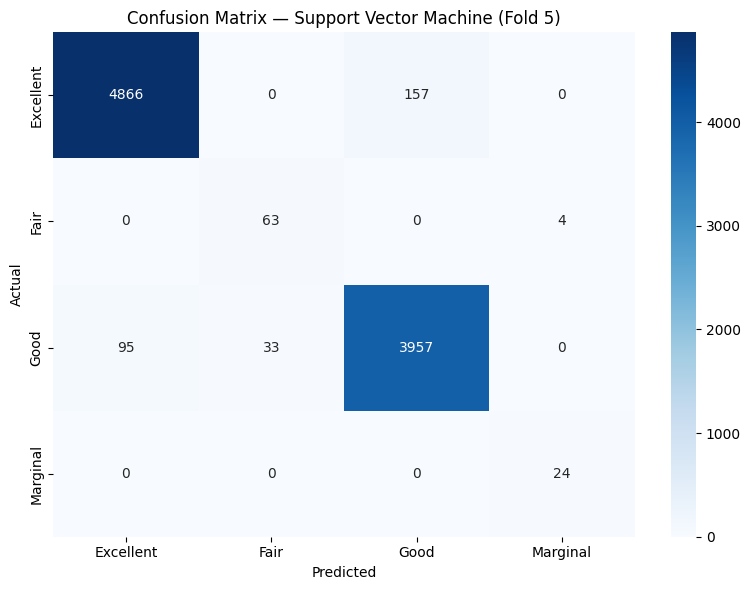

              precision    recall  f1-score   support

   Excellent       0.98      0.97      0.97      5023
        Fair       0.66      0.94      0.77        67
        Good       0.96      0.97      0.97      4085
    Marginal       0.86      1.00      0.92        24

    accuracy                           0.97      9199
   macro avg       0.86      0.97      0.91      9199
weighted avg       0.97      0.97      0.97      9199



In [5]:
from sklearn.svm import SVC                  # SVC = Support Vector Classifier (SVM for classification tasks)

# ── Define the SVM model ──────────────────────────────────────────────────────
model = SVC(
    kernel='rbf',        # RBF (Radial Basis Function) kernel: maps data to a higher-dimensional space
                         # Allows SVM to find non-linear decision boundaries
                         # Formula: K(x,z) = exp(−γ ‖x−z‖²)
    C=1.0,               # Regularisation parameter: controls trade-off between margin width and misclassification
                         # C=1.0 is the default balanced starting point
                         # Higher C → narrower margin, fewer training errors (risk of overfitting)
                         # Lower C → wider margin, more training errors (more generalisation)
    gamma='scale',       # gamma defines how far the influence of a single training example reaches
                         # 'scale' → auto-set as 1/(n_features × X.var()) — adapts to this dataset's variance
    random_state=42      # fixes randomness in the solver for reproducibility
)
model_name = 'Support Vector Machine'        # label used in print statements and plot titles

# ── Storage for cross-validation results ─────────────────────────────────────
all_f1_svm = []                              # collect macro F1 score from each of the 5 folds (TEST data)
train_f1_svm = []                            # macro F1 on the real (un-SMOTEd) TRAINING fold — used for the overfitting check
all_reports_svm = []                         # collect full classification report dict from each fold

# ═══════════════════════════════════════════════════════════════
#  5-FOLD STRATIFIED CROSS-VALIDATION LOOP
#  Runs 5 iterations; each uses a different 20% as test data
# ═══════════════════════════════════════════════════════════════
for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):
# skf.split(X,y) → generates 5 pairs of (train_indices, test_indices)
# enumerate → adds fold counter (0, 1, 2, 3, 4)

    # ── Split data for this fold ──────────────────────────────────────────────
    X_train, X_test = X[train_idx], X[test_idx]
    # X[train_idx]: selects the ~36,797 rows for training (80%)
    # X[test_idx]:  selects the ~9,200 rows for testing  (20%)
    y_train, y_test = y[train_idx], y[test_idx]  # same split for labels

    # ── Scale features (CRITICAL: fit ONLY on train, never on test) ───────────
    X_train = scaler.fit_transform(X_train)  # fit: compute mean+std FROM training data; then scale training data
    X_test  = scaler.transform(X_test)       # transform: apply the SAME mean+std to test data (no refit)
    # If we fit_transform on X_test: the scaler would learn test data's mean+std
    # That leaks information about the test set into scaling → artificially good results

    # ── SMOTE — balance training fold ONLY ───────────────────────────────────
    smote = SMOTE(random_state=42)           # new SMOTE object each fold (same seed for reproducibility)
    X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
    # fit_resample:
    #   1. Finds minority classes (≈269 Fair and ≈97 Marginal in each training fold)
    #   2. For each minority sample, finds its K nearest minority neighbours
    #   3. Generates synthetic samples by interpolating between real neighbours in 8D space
    #   4. Outputs balanced training set (all 4 classes have equal count)
    # X_test is NEVER touched by SMOTE → test set always reflects real-world imbalance

    # ── Train SVM on balanced training data ───────────────────────────────────
    model.fit(X_train_bal, y_train_bal)      # SVM finds the optimal hyperplane separating 4 classes
                                             # NOTE: SVM is O(n²) in training samples; slowest of the 4 algorithms

    # ── Predict on REAL (imbalanced) test fold ────────────────────────────────
    y_pred = model.predict(X_test)           # for each test sample: compute distance to hyperplane → assign class

    # ── Calculate Macro F1 for this fold ─────────────────────────────────────
    f1 = f1_score(y_test, y_pred, average='macro')
    # macro: compute F1 for each class separately, then take the unweighted mean
    # This treats Marginal (≈24 test samples) and Excellent (≈5,000 test samples) equally
    all_f1_svm.append(f1)                    # store this fold's score
    f1_train = f1_score(y_train, model.predict(X_train), average='macro')
    # same metric on the data the model was fitted on (real training rows, not synthetic ones)
    # a big train-vs-test gap = overfitting
    train_f1_svm.append(f1_train)

    all_reports_svm.append(
        classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
    )                                        # store dict: {class: {precision, recall, f1, support}}

    print(f"Fold {fold+1} Macro F1: test {f1:.4f} | train {f1_train:.4f}")   # live progress per fold

# ── Summary across all 5 folds ────────────────────────────────────────────────
print(f"\n{model_name} — Mean Macro F1: {np.mean(all_f1_svm):.4f} ± {np.std(all_f1_svm):.4f}")
# np.mean → average F1 across 5 folds = overall performance estimate
# np.std  → standard deviation across folds: small std = model is stable/consistent

# ── Confusion Matrix (last fold only — for visualisation) ────────────────────
cm = confusion_matrix(y_test, y_pred)        # actual vs predicted for fold 5
# cm[i][j] = number of samples of actual class i predicted as class j
# Diagonal = correct predictions; off-diagonal = errors

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,                              # print count inside each cell
    fmt='d',                                 # format as integer (not 1.2e+03 notation)
    cmap='Blues',                            # darker blue = more samples in that cell
    xticklabels=le.classes_,                 # x-axis = predicted class names
    yticklabels=le.classes_                  # y-axis = actual class names
)
plt.title(f'Confusion Matrix — {model_name} (Fold 5)')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig(f'cm_{model_name.lower().replace(" ","_")}.png')
plt.show()

# ── Full classification report (last fold) ────────────────────────────────────
print(classification_report(y_test, y_pred, target_names=le.classes_))
# Precision: of everything predicted as "Marginal", how many were actually Marginal?
# Recall:    of all actual "Marginal" samples, how many did we correctly catch?
# F1:        harmonic mean of Precision and Recall
# Support:   actual number of test samples per class in fold 5


##Classifier: Naive Bayes
Fastest to train. Assumes features are independent given the class and (for GaussianNB) bell-shaped within each class. Check the measured correlations and skew before blaming either assumption for its score.

Fold 1 Macro F1: 0.7150
Fold 2 Macro F1: 0.7382
Fold 3 Macro F1: 0.7233
Fold 4 Macro F1: 0.7430
Fold 5 Macro F1: 0.7545

Naive Bayes — Mean Macro F1: 0.7348 ± 0.0141


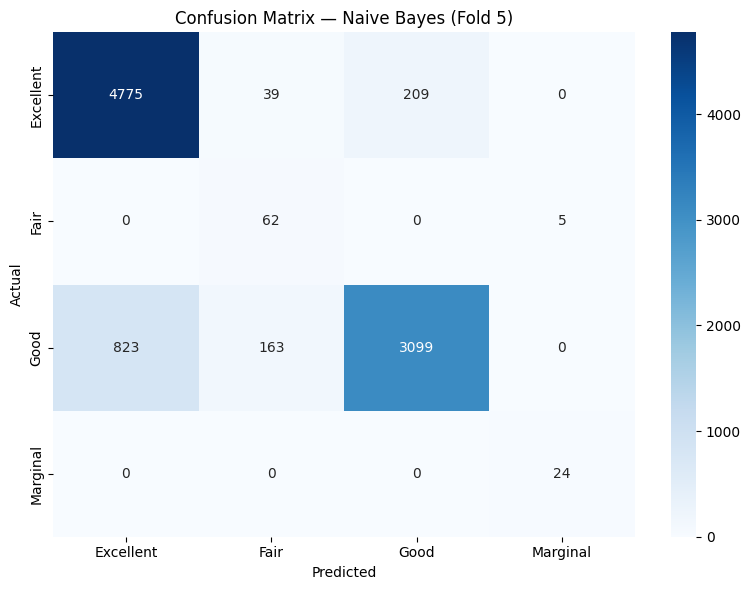

              precision    recall  f1-score   support

   Excellent       0.85      0.95      0.90      5023
        Fair       0.23      0.93      0.37        67
        Good       0.94      0.76      0.84      4085
    Marginal       0.83      1.00      0.91        24

    accuracy                           0.87      9199
   macro avg       0.71      0.91      0.75      9199
weighted avg       0.89      0.87      0.87      9199



In [6]:
# ═══════════════════════════════════════════════════════════════
#  NAIVE BAYES — How it works
#  Uses Bayes' theorem: P(class|features) ∝ P(class) × ∏P(feature_i|class)
#  "Naive": assumes ALL features are independent of each other
#  Measured feature correlations in this dataset are mostly weak (see the printed
#  heatmap readout), so independence is NOT obviously the main problem.
#  A more likely issue: GaussianNB assumes bell-shaped features, but Ammonia,
#  Orthophosphate, Nitrogen, Nitrate and BOD are strongly right-skewed.
#  Compare the result against the other models in the comparison section.
# ═══════════════════════════════════════════════════════════════

from sklearn.naive_bayes import GaussianNB   # GaussianNB: assumes each feature follows a Gaussian distribution per class

model_nb = GaussianNB()
# GaussianNB has no critical hyperparameters to tune
# It simply stores the mean and variance of each feature per class during training
# Training is instantaneous — just computing statistics

model_name_nb = 'Naive Bayes'

# ── Storage for cross-validation results ─────────────────────────────────────
all_f1_nb = []                               # fold-level macro F1 scores (TEST data)
train_f1_nb = []                             # fold-level macro F1 on the real training fold (overfitting check)
all_reports_nb = []                          # fold-level full classification reports

# ═══════════════════════════════════════════════════════════════
#  5-FOLD CROSS-VALIDATION (same structure as SVM)
# ═══════════════════════════════════════════════════════════════
for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    X_train = scaler.fit_transform(X_train)  # scale: fit on train only
    X_test  = scaler.transform(X_test)       # scale: apply training mean+std to test data

    smote = SMOTE(random_state=42)           # new SMOTE object per fold
    X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)
    # SMOTE balances training fold before NB sees it

    model_nb.fit(X_train_bal, y_train_bal)
    # NB training: for each class, compute mean and variance of each feature
    # Stores 4 × 8 = 32 mean values and 32 variance values — that's all
    # No iterative optimisation — training is near-instant

    y_pred_nb = model_nb.predict(X_test)
    # For each test sample: compute P(class) × ∏ P(feature_i | class) for each class
    # Predict the class with the highest probability
    # Uses Gaussian PDF: P(x|class) = (1/√(2πσ²)) × exp(−(x−μ)²/(2σ²))

    f1 = f1_score(y_test, y_pred_nb, average='macro')
    all_f1_nb.append(f1)
    f1_train = f1_score(y_train, model_nb.predict(X_train), average='macro')
    train_f1_nb.append(f1_train)
    all_reports_nb.append(
        classification_report(y_test, y_pred_nb, target_names=le.classes_, output_dict=True)
    )
    print(f"Fold {fold+1} Macro F1: test {f1:.4f} | train {f1_train:.4f}")

print(f"\n{model_name_nb} — Mean Macro F1: {np.mean(all_f1_nb):.4f} ± {np.std(all_f1_nb):.4f}")

# ── Confusion Matrix (last fold) ──────────────────────────────────────────────
cm_nb = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_nb, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Confusion Matrix — {model_name_nb} (Fold 5)')
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig(f'cm_{model_name_nb.lower().replace(" ","_")}.png')
plt.show()

print(classification_report(y_test, y_pred_nb, target_names=le.classes_))


##Classifier: Decision Tree
Learns human-readable IF-THEN rules (e.g., IF Ammonia is high AND Orthophosphate is high THEN Marginal). Interpretable but prone to overfitting without depth limits.

Fold 1 Macro F1: 0.9388
Fold 2 Macro F1: 0.9241
Fold 3 Macro F1: 0.8940
Fold 4 Macro F1: 0.9266
Fold 5 Macro F1: 0.9274

Decision Tree — Mean Macro F1: 0.9222 ± 0.0150


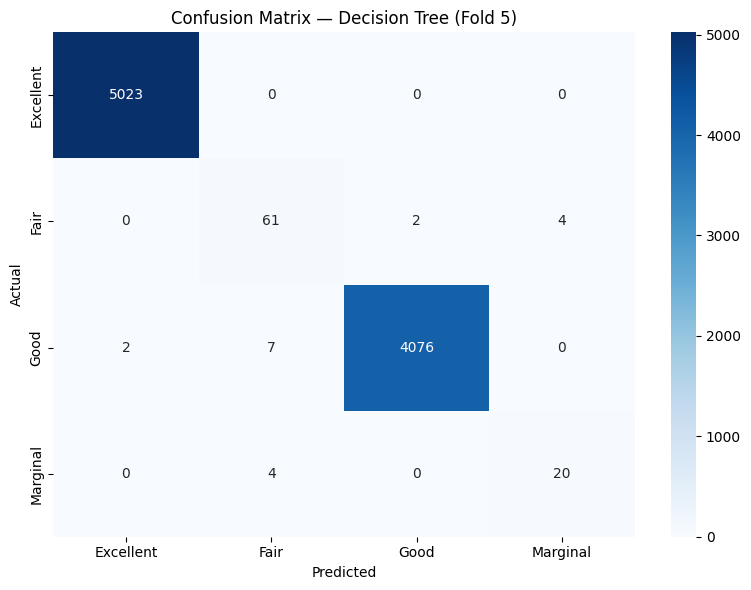

              precision    recall  f1-score   support

   Excellent       1.00      1.00      1.00      5023
        Fair       0.85      0.91      0.88        67
        Good       1.00      1.00      1.00      4085
    Marginal       0.83      0.83      0.83        24

    accuracy                           1.00      9199
   macro avg       0.92      0.94      0.93      9199
weighted avg       1.00      1.00      1.00      9199



In [13]:
# ═══════════════════════════════════════════════════════════════
#  DECISION TREE — How it works
#  Recursively splits the data using the feature+threshold that
#  best separates classes (measured by Gini impurity)
#  Produces human-readable IF-THEN rules
#  Risk: without depth limits, the tree memorises training data (overfitting)
#  (Result: see comparison section — no result is assumed here)
# ═══════════════════════════════════════════════════════════════

from sklearn.tree import DecisionTreeClassifier

model_dt = DecisionTreeClassifier(
    max_depth=10,          # limit tree to 10 levels deep → prevents overfitting
                           # unlimited depth: the tree keeps splitting until leaves are pure → memorises training data
    min_samples_leaf=5,    # each leaf node must contain at least 5 training samples
                           # prevents very specific rules that apply to only 1-2 samples
    criterion='gini',      # Gini impurity: measures how "mixed" (impure) a node is
                           # Gini = 1 − Σ(p_i²) where p_i = fraction of class i in node
                           # Pure node (all one class): Gini = 0
                           # Maximum mixed node (equal classes): Gini = 0.75 (for 4 classes)
    random_state=42        # fixes random tie-breaking in split selection
)
model_name_dt = 'Decision Tree'

all_f1_dt = []
train_f1_dt = []               # macro F1 on the real training fold (overfitting check)
all_reports_dt = []
feature_importances_dt = []    # ← EXTRA: stores Gini-based feature importance per fold
                                # Decision Tree has built-in feature importance — no extra computation needed

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)

    smote = SMOTE(random_state=42)
    X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

    model_dt.fit(X_train_bal, y_train_bal)
    # DT training: recursively finds the best (feature, threshold) pair that
    # minimises Gini impurity at each node
    # Stops when max_depth=10 is reached OR min_samples_leaf=5 is violated

    y_pred_dt = model_dt.predict(X_test)
    # Prediction: pass each test sample down the tree, following the learned rules
    # until reaching a leaf node → return that leaf's majority class

    f1 = f1_score(y_test, y_pred_dt, average='macro')
    all_f1_dt.append(f1)
    f1_train = f1_score(y_train, model_dt.predict(X_train), average='macro')
    train_f1_dt.append(f1_train)
    all_reports_dt.append(
        classification_report(y_test, y_pred_dt, target_names=le.classes_, output_dict=True)
    )

    feature_importances_dt.append(model_dt.feature_importances_)
    # feature_importances_: array of shape (8,)
    # Each value = total Gini impurity reduction caused by splits on that feature
    # across the entire tree, normalised so all 8 values sum to 1.0
    # Stored per fold so we can average across all 5 folds for a stable estimate

    print(f"Fold {fold+1} Macro F1: test {f1:.4f} | train {f1_train:.4f}")

print(f"\n{model_name_dt} — Mean Macro F1: {np.mean(all_f1_dt):.4f} ± {np.std(all_f1_dt):.4f}")

cm_dt = confusion_matrix(y_test, y_pred_dt)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Confusion Matrix — {model_name_dt} (Fold 5)')
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig(f'cm_{model_name_dt.lower().replace(" ","_")}.png')
plt.show()

print(classification_report(y_test, y_pred_dt, target_names=le.classes_))


##Classifier: Random Forest
An ensemble of 100 Decision Trees. Bagging (bootstrap + feature subsampling) makes it far more robust than a single tree.  

Fold 1 Macro F1: 0.9514
Fold 2 Macro F1: 0.9346
Fold 3 Macro F1: 0.9157
Fold 4 Macro F1: 0.9786
Fold 5 Macro F1: 0.9539

Random Forest — Mean Macro F1: 0.9468 ± 0.0210


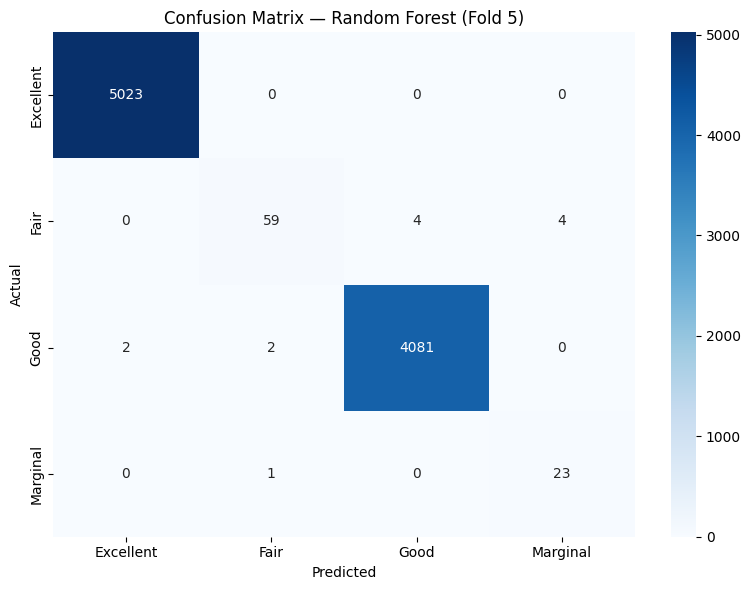

              precision    recall  f1-score   support

   Excellent       1.00      1.00      1.00      5023
        Fair       0.95      0.88      0.91        67
        Good       1.00      1.00      1.00      4085
    Marginal       0.85      0.96      0.90        24

    accuracy                           1.00      9199
   macro avg       0.95      0.96      0.95      9199
weighted avg       1.00      1.00      1.00      9199



In [15]:
# ═══════════════════════════════════════════════════════════════
#  RANDOM FOREST — How it works
#  Builds 100 Decision Trees independently, each trained on:
#    • A BOOTSTRAP SAMPLE: rows drawn WITH replacement, same size as the training set
#      (≈63% of distinct rows appear in each sample; the rest are left out)
#    • A RANDOM FEATURE SUBSET: sqrt(8) ≈ 3 features considered per split
#  Final prediction = MAJORITY VOTE across all 100 trees
#  WHY this beats a single DT:
#    • Each tree sees different data → different errors → errors cancel out
#    • Feature subsampling prevents all trees from making identical splits
#    • Variance is drastically reduced (bagging = bootstrap aggregating)
#  Literature support: Elmotawakkil et al. (2025) found RF and XGBoost
#  outperform DT, SVM, NB on water quality classification
#  (Result: see comparison section — no result is assumed here)
# ═══════════════════════════════════════════════════════════════

from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=100,      # grow 100 independent decision trees
                           # more trees = more stable predictions; diminishing returns after ~200
    max_features='sqrt',   # each tree sees only sqrt(8) ≈ 3 features at each split node
                           # prevents all trees from always splitting on the same dominant feature
    criterion='gini',      # use Gini impurity to choose the best split (same as DT above)
    n_jobs=-1,             # use ALL available CPU cores → parallel tree training → much faster
    random_state=42        # fixed seed for reproducible random sampling
)
model_name_rf = 'Random Forest'

all_f1_rf = []
train_f1_rf = []              # macro F1 on the real training fold (overfitting check)
all_reports_rf = []
feature_importances_rf = []   # ← stores averaged Gini importance across all 100 trees per fold

for fold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    X_train = scaler.fit_transform(X_train)
    X_test  = scaler.transform(X_test)

    smote = SMOTE(random_state=42)
    X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

    model_rf.fit(X_train_bal, y_train_bal)
    # Trains all 100 trees in PARALLEL (n_jobs=-1 uses all cores)
    # Each tree:
    #   1. Draws a bootstrap sample (random rows with replacement)
    #   2. Grows a full depth tree using Gini + random feature subsets at each node

    y_pred_rf = model_rf.predict(X_test)
    # Prediction: each of the 100 trees votes for a class
    # Final answer = class with the most votes (majority voting)

    f1 = f1_score(y_test, y_pred_rf, average='macro')
    all_f1_rf.append(f1)
    f1_train = f1_score(y_train, model_rf.predict(X_train), average='macro')
    train_f1_rf.append(f1_train)
    all_reports_rf.append(
        classification_report(y_test, y_pred_rf, target_names=le.classes_, output_dict=True)
    )

    feature_importances_rf.append(model_rf.feature_importances_)
    # model_rf.feature_importances_: averaged Gini importance across all 100 trees
    # More stable than a single DT's importance because it averages over 100 trees

    print(f"Fold {fold+1} Macro F1: test {f1:.4f} | train {f1_train:.4f}")

print(f"\n{model_name_rf} — Mean Macro F1: {np.mean(all_f1_rf):.4f} ± {np.std(all_f1_rf):.4f}")

cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Confusion Matrix — {model_name_rf} (Fold 5)')
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig(f'cm_{model_name_rf.lower().replace(" ","_")}.png')
plt.show()

print(classification_report(y_test, y_pred_rf, target_names=le.classes_))


##Comparative Analysis
**"Identify the most reliable classifier for imbalanced WQI data"** — compare all 4 algorithms side-by-side.


══ Classifier Comparison (5-Fold Stratified CV) ══
                        Mean Macro F1    Std
Random Forest                  0.9468 0.0210
Decision Tree                  0.9222 0.0150
Support Vector Machine         0.9084 0.0099
Naive Bayes                    0.7348 0.0141

 OUTCOME 1 — Best Classifier: Random Forest
   Mean Macro F1 = 0.9468 over 5-fold stratified cross-validation


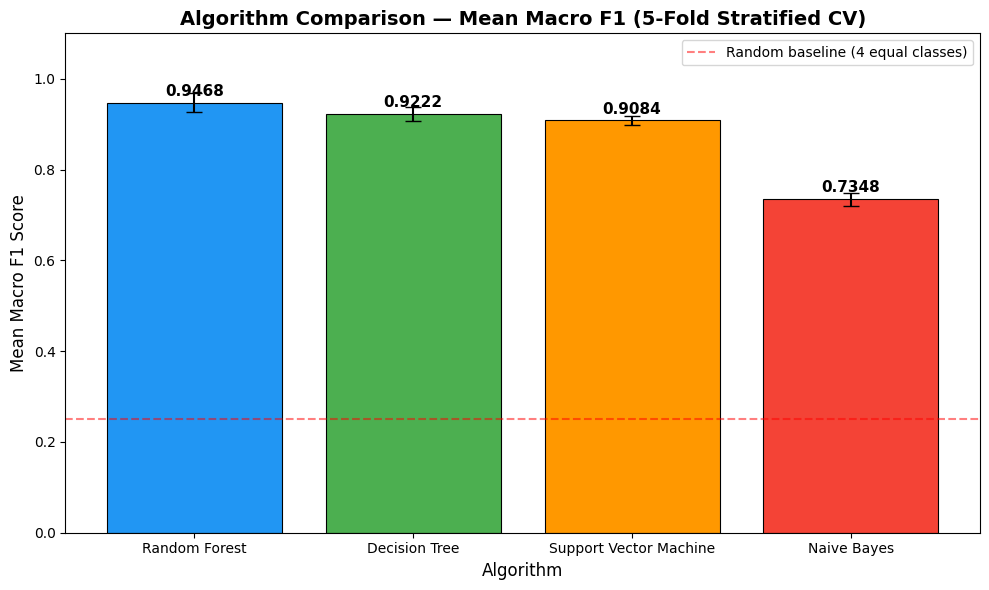

In [11]:
# ═══════════════════════════════════════════════════════════════
#  OUTCOME 1: Identify the most reliable classifier for
#  imbalanced WQI data
#  Method: compare Mean Macro F1 ± Std across 5-fold CV
# ═══════════════════════════════════════════════════════════════

# ── Build summary table ───────────────────────────────────────────────────────
results_summary = {                          # dict: algorithm name → [mean macro F1, std across folds]
    'Naive Bayes':            [np.mean(all_f1_nb),  np.std(all_f1_nb)],
    'Decision Tree':          [np.mean(all_f1_dt),  np.std(all_f1_dt)],
    'Random Forest':          [np.mean(all_f1_rf),  np.std(all_f1_rf)],
    'Support Vector Machine': [np.mean(all_f1_svm), np.std(all_f1_svm)],
}

summary_df = pd.DataFrame(results_summary, index=['Mean Macro F1', 'Std']).T
# .T = transpose: rows become columns → each row = one algorithm
summary_df = summary_df.sort_values('Mean Macro F1', ascending=False)
# sort best → worst for easy ranking

print("\n══ Classifier Comparison (5-Fold Stratified CV) ══")
print(summary_df.to_string(float_format='%.4f'))   # print full table with 4 decimal places

best_model_name = summary_df.index[0]        # top row = highest F1 = best algorithm
best_f1 = summary_df.loc[best_model_name, 'Mean Macro F1']
print(f"\n OUTCOME 1 — Best Classifier: {best_model_name}")
print(f"   Mean Macro F1 = {best_f1:.4f} over 5-fold stratified cross-validation")

# ── Bar Chart with Error Bars ─────────────────────────────────────────────────
# Error bars (yerr) show ± std — how stable each algorithm is across 5 folds
fig, ax = plt.subplots(figsize=(10, 6))

colors = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']   # one colour per algorithm bar

bars = ax.bar(
    summary_df.index,                        # x-axis: algorithm names (sorted best → worst)
    summary_df['Mean Macro F1'],             # bar height: mean F1 across 5 folds
    yerr=summary_df['Std'],                  # error bars: ± std; shows cross-fold consistency
    capsize=6,                               # horizontal caps at top/bottom of error bars
    color=colors[:len(summary_df)],          # apply the 4 colours
    edgecolor='black',                       # black border on each bar
    linewidth=0.8
)

# Print exact F1 value above each bar
for bar, (_, row) in zip(bars, summary_df.iterrows()):
    ax.text(
        bar.get_x() + bar.get_width() / 2,  # x position = centre of the bar
        bar.get_height() + 0.008,            # y position = slightly above bar top
        f"{row['Mean Macro F1']:.4f}",       # text = mean F1 to 4 decimal places
        ha='center', va='bottom', fontsize=11, fontweight='bold'
    )

ax.set_title('Algorithm Comparison — Mean Macro F1 (5-Fold Stratified CV)',
             fontsize=14, fontweight='bold')
ax.set_ylabel('Mean Macro F1 Score', fontsize=12)
ax.set_xlabel('Algorithm', fontsize=12)
ax.set_ylim(0, 1.10)                         # y-axis 0 to 1.10; leaves space above the highest bar
ax.axhline(y=0.25, color='red', linestyle='--', alpha=0.5,
           label='Stratified random guessing (≈0.25)')
# Dashed red line: guessing classes at random in proportion to their frequency gives macro F1 ≈ 1/4
# (the majority-class baseline is computed in the robustness section below)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig('outcome1_comparison_bar_chart.png', dpi=150)
plt.show()


##Robustness Checks
Fold-to-fold variability, train-vs-test gap, trivial baselines, per-class scores, and a no-SMOTE / class-weight comparison. These test whether the headline macro F1 numbers can be trusted.

In [ ]:
# ═══════════════════════════════════════════════════════════════
#  CHECK 1 — Fold variability, train-vs-test gap, baselines, per-class F1
# ═══════════════════════════════════════════════════════════════
cv_store = {                                   # name → (test F1 per fold, train F1 per fold, classification reports per fold)
    'Naive Bayes':            (all_f1_nb,  train_f1_nb,  all_reports_nb),
    'Decision Tree':          (all_f1_dt,  train_f1_dt,  all_reports_dt),
    'Random Forest':          (all_f1_rf,  train_f1_rf,  all_reports_rf),
    'Support Vector Machine': (all_f1_svm, train_f1_svm, all_reports_svm),
}

# ── 1a. Test-score spread and train-vs-test gap ──────────────────────────────
rows = []
for name, (test_f1, train_f1, _) in cv_store.items():
    rows.append({
        'Model': name,
        'Test mean': np.mean(test_f1),
        'Test std (ddof=0)': np.std(test_f1),            # same convention as the rest of the notebook
        'Test std (ddof=1)': np.std(test_f1, ddof=1),    # sample std — more conservative with only 5 folds
        'Test min': np.min(test_f1),
        'Test max': np.max(test_f1),
        'Train mean': np.mean(train_f1),
        'Train-Test gap': np.mean(train_f1) - np.mean(test_f1),
    })
gap_df = pd.DataFrame(rows).set_index('Model').sort_values('Test mean', ascending=False)
print("══ Fold variability and train-vs-test gap (macro F1) ══")
print(gap_df.round(4).to_string())
for name, row in gap_df.iterrows():
    flag = "LARGE gap → likely overfitting" if row['Train-Test gap'] > 0.05 else "small gap"
    print(f"   {name:<24} gap = {row['Train-Test gap']:+.4f}  ({flag}; threshold 0.05 is a rule of thumb)")

# ── 1b. Trivial baselines on the same folds ──────────────────────────────────
dummy_scores = {}
for strategy in ['most_frequent', 'stratified']:
    sc = []
    for tr_i, te_i in skf.split(X, y):
        d = DummyClassifier(strategy=strategy, random_state=42).fit(X[tr_i], y[tr_i])
        sc.append(f1_score(y[te_i], d.predict(X[te_i]), average='macro'))
    dummy_scores[strategy] = np.mean(sc)
print(f"\n══ Trivial baselines (macro F1) ══")
print(f"   Always predict the majority class : {dummy_scores['most_frequent']:.4f}")
print(f"   Random guess by class frequency   : {dummy_scores['stratified']:.4f}")

# ── 1c. Per-class F1 (mean ± std over the 5 test folds) ──────────────────────
pc = {}
for name, (_, _, reps) in cv_store.items():
    pc[name] = {c: f"{np.mean([r[c]['f1-score'] for r in reps]):.3f} ± {np.std([r[c]['f1-score'] for r in reps]):.3f}"
                for c in le.classes_}
print("\n══ Per-class F1 across 5 folds (mean ± std) ══")
print(pd.DataFrame(pc).T.loc[gap_df.index].to_string())
print("Note: Marginal has only ≈24 test rows per fold, so its per-fold F1 is inherently noisy.")

# ── 1d. Is the top model's win consistent fold by fold? ──────────────────────
best_a, best_b = gap_df.index[0], gap_df.index[1]
d_ab = np.array(cv_store[best_a][0]) - np.array(cv_store[best_b][0])
print(f"\n══ Paired fold-by-fold: {best_a} minus {best_b} ══")
print("   per-fold difference:", np.round(d_ab, 4))
print(f"   {best_a} is ahead in {(d_ab > 0).sum()} of 5 folds; mean difference {d_ab.mean():+.4f}")


In [ ]:
# ═══════════════════════════════════════════════════════════════
#  CHECK 2 — Does SMOTE actually help? Compare three imbalance strategies
#     (a) no resampling at all
#     (b) class weights (minority errors cost more; no synthetic data)
#     (c) SMOTE on training folds — already computed above, reused here
#  Same stratified folds; scaler fitted on the training fold only.
# ═══════════════════════════════════════════════════════════════
i_fair, i_marg = list(le.classes_).index('Fair'), list(le.classes_).index('Marginal')

def cv_without_smote(make_model, balanced_sample_weight=False):
    macro, per_class = [], []
    for tr_i, te_i in skf.split(X, y):
        sc = StandardScaler().fit(X[tr_i])                # fresh scaler, fitted on training rows only
        Xtr, Xte = sc.transform(X[tr_i]), sc.transform(X[te_i])
        m = make_model()
        if balanced_sample_weight:                        # for models without a class_weight argument (GaussianNB)
            m.fit(Xtr, y[tr_i], sample_weight=compute_sample_weight('balanced', y[tr_i]))
        else:
            m.fit(Xtr, y[tr_i])
        pred = m.predict(Xte)
        macro.append(f1_score(y[te_i], pred, average='macro'))
        per_class.append(f1_score(y[te_i], pred, average=None, labels=range(len(le.classes_))))
    return np.array(macro), np.array(per_class)

variants = {
    'Naive Bayes': {
        'No resampling': dict(make_model=lambda: clone(model_nb)),
        'Class weights': dict(make_model=lambda: clone(model_nb), balanced_sample_weight=True),
    },
    'Decision Tree': {
        'No resampling': dict(make_model=lambda: clone(model_dt)),
        'Class weights': dict(make_model=lambda: clone(model_dt).set_params(class_weight='balanced')),
    },
    'Random Forest': {
        'No resampling': dict(make_model=lambda: clone(model_rf)),
        'Class weights': dict(make_model=lambda: clone(model_rf).set_params(class_weight='balanced')),
    },
    'Support Vector Machine': {
        'No resampling': dict(make_model=lambda: clone(model)),
        'Class weights': dict(make_model=lambda: clone(model).set_params(class_weight='balanced')),
    },
}

rows = []
for name, strategies in variants.items():
    for strat, kwargs in strategies.items():
        macro, pcl = cv_without_smote(**kwargs)
        rows.append({'Model': name, 'Strategy': strat,
                     'Macro F1': f"{macro.mean():.4f} ± {macro.std():.4f}",
                     'Fair F1': f"{pcl[:, i_fair].mean():.3f}", 'Marginal F1': f"{pcl[:, i_marg].mean():.3f}"})
    reps = cv_store[name][2]
    smote_macro = np.array(cv_store[name][0])
    rows.append({'Model': name, 'Strategy': 'SMOTE (main results)',
                 'Macro F1': f"{smote_macro.mean():.4f} ± {smote_macro.std():.4f}",
                 'Fair F1': f"{np.mean([r['Fair']['f1-score'] for r in reps]):.3f}",
                 'Marginal F1': f"{np.mean([r['Marginal']['f1-score'] for r in reps]):.3f}"})

strategy_df = pd.DataFrame(rows).set_index(['Model', 'Strategy'])
print("══ Imbalance-handling comparison (5-fold stratified CV, macro F1 and minority-class F1) ══")
print(strategy_df.to_string())


In [ ]:
# ═══════════════════════════════════════════════════════════════
#  CHECK 3 — Temporal holdout: train on the earlier years, test on the later ones
#  Why: the main CV shuffles rows of a time series, so near-in-time rows can sit in both
#  train and test. If scores collapse on a time-ordered split, the CV numbers are optimistic.
#  Marginal rows are rare after 2012, so its score here rests on very few samples.
# ═══════════════════════════════════════════════════════════════
years = pd.to_datetime(df['Date'], format='%d-%m-%Y').dt.year.values
tr_mask, te_mask = years <= 2012, years >= 2013
print(f"Train years 2001–2012: {tr_mask.sum()} rows | Test years 2013–2017: {te_mask.sum()} rows")
print("Test-set class counts:", dict(zip(le.classes_, np.bincount(y[te_mask], minlength=len(le.classes_)))))

sc_t = StandardScaler().fit(X[tr_mask])
Xtr_t, Xte_t = sc_t.transform(X[tr_mask]), sc_t.transform(X[te_mask])
Xtr_tb, ytr_tb = SMOTE(random_state=42).fit_resample(Xtr_t, y[tr_mask])

holdout_rows = []
for name, mk in [('Naive Bayes', model_nb), ('Decision Tree', model_dt),
                 ('Random Forest', model_rf), ('Support Vector Machine', model)]:
    m = clone(mk).fit(Xtr_tb, ytr_tb)
    pred = m.predict(Xte_t)
    holdout_f1 = f1_score(y[te_mask], pred, average='macro')
    pcl = f1_score(y[te_mask], pred, average=None, labels=range(len(le.classes_)))
    holdout_rows.append({'Model': name, 'Temporal holdout F1': holdout_f1,
                         'Shuffled-CV F1': np.mean(cv_store[name][0]),
                         **{f'{c} F1': v for c, v in zip(le.classes_, pcl)}})
holdout_df = pd.DataFrame(holdout_rows).set_index('Model')
holdout_df['Drop vs CV'] = holdout_df['Temporal holdout F1'] - holdout_df['Shuffled-CV F1']
print("\n══ Temporal holdout vs shuffled CV (macro F1) ══")
print(holdout_df.round(4).to_string())


##Feature Importance
**"Determine physicochemical parameters with strongest predictive impact"**

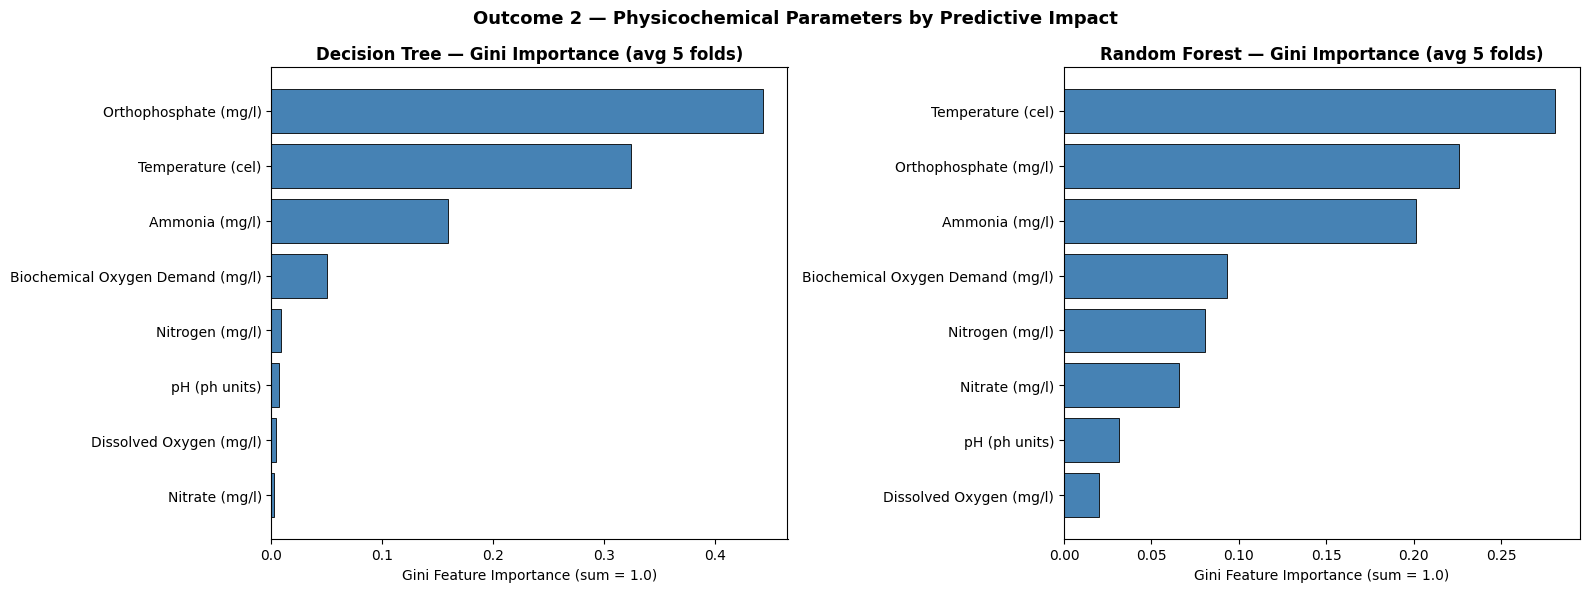

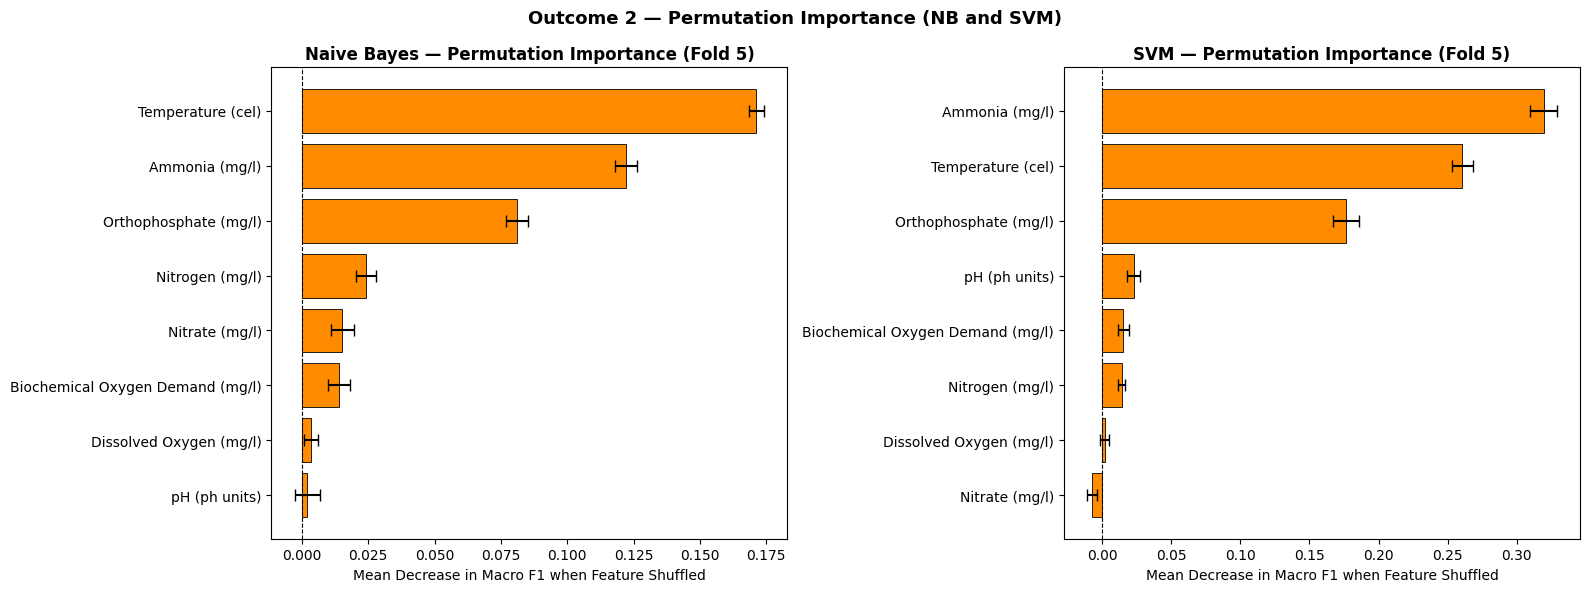


══ Feature Importance Consensus Ranking (1 = Most Important) ══
                                  Decision Tree  Random Forest  Naive Bayes  SVM  Average Rank
Temperature (cel)                           2.0            1.0          1.0  2.0          1.50
Ammonia (mg/l)                              3.0            3.0          2.0  1.0          2.25
Orthophosphate (mg/l)                       1.0            2.0          3.0  3.0          2.25
Biochemical Oxygen Demand (mg/l)            4.0            4.0          6.0  5.0          4.75
Nitrogen (mg/l)                             5.0            5.0          4.0  6.0          5.00
pH (ph units)                               6.0            7.0          8.0  4.0          6.25
Nitrate (mg/l)                              8.0            6.0          5.0  8.0          6.75
Dissolved Oxygen (mg/l)                     7.0            8.0          7.0  7.0          7.25

OUTCOME 2 — Most Impactful Physicochemical Parameter: Temperature (cel)
   This

In [12]:
# ═══════════════════════════════════════════════════════════════
#  OUTCOME 2: Determine physicochemical parameters with
#  strongest predictive impact
#
#  Two methods used (by algorithm type):
#  A) Gini-based importance  → Decision Tree, Random Forest
#     Built-in: total Gini impurity reduction per feature, normalised
#  B) Permutation importance → Naive Bayes, SVM
#     Model-agnostic: shuffle one feature at a time → measure Macro F1 drop
#     Bigger drop = feature was important (model relied on it)
# ═══════════════════════════════════════════════════════════════

from sklearn.inspection import permutation_importance   # scikit-learn's built-in permutation importance

feature_names = features

# ── PART A: Gini Importance — Decision Tree and Random Forest ─────────────────

# Average importance across all 5 folds for stability
mean_imp_dt = np.mean(feature_importances_dt, axis=0)
# feature_importances_dt = list of 5 arrays, each of shape (8,)
# np.mean(axis=0) = element-wise mean → single array of shape (8,)
# Each value = average contribution of that feature to Gini reduction over 5 folds

mean_imp_rf = np.mean(feature_importances_rf, axis=0)
# Same process for Random Forest (but each fold's importance is already averaged across 100 trees)

# Plot DT vs RF Gini importance side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))   # 1 row, 2 columns

for ax, importances, title in zip(
    axes,
    [mean_imp_dt, mean_imp_rf],
    ['Decision Tree — Gini Importance (avg 5 folds)',
     'Random Forest — Gini Importance (avg 5 folds)']
):
    sorted_idx = np.argsort(importances)[::-1]   # sort indices: highest importance first
    ax.barh(
        [feature_names[i] for i in sorted_idx],  # y-axis: feature names in sorted order
        importances[sorted_idx],                   # bar width: importance value
        color='steelblue', edgecolor='black', linewidth=0.6
    )
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Gini Feature Importance (sum = 1.0)')
    # All 8 values sum to 1.0 — shows relative contribution of each feature
    ax.invert_yaxis()                             # most important feature at the TOP

plt.suptitle('Outcome 2 — Physicochemical Parameters by Predictive Impact',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outcome2_gini_importance_dt_rf.png', dpi=150)
plt.show()

# ── PART B: Permutation Importance — Naive Bayes and SVM ─────────────────────
# Re-extract the last fold's data (same indices as the final loop iteration)
# NOTE: NB/SVM importance comes from this single fold only; the check below repeats it over all 5 folds for DT/RF/NB
all_splits = list(skf.split(X, y))          # materialise all 5 (train_idx, test_idx) pairs into a list
train_idx_last, test_idx_last = all_splits[-1]  # take the last (5th) fold's indices

# Scale last fold
X_tr_p = scaler.fit_transform(X[train_idx_last])   # fit+scale on training portion of fold 5
X_te_p = scaler.transform(X[test_idx_last])         # scale test portion using train's mean+std
y_tr_p = y[train_idx_last]
y_te_p = y[test_idx_last]

# Balance training data with SMOTE
smote_p = SMOTE(random_state=42)
X_tr_bal_p, y_tr_bal_p = smote_p.fit_resample(X_tr_p, y_tr_p)

# Refit NB and SVM on this fold (need fresh models fitted on this specific fold's data)
model_nb.fit(X_tr_bal_p, y_tr_bal_p)        # refit Naive Bayes
model.fit(X_tr_bal_p, y_tr_bal_p)           # refit SVM (model = the SVC defined in the SVM cell above)

# Compute permutation importance for NB
perm_nb = permutation_importance(
    model_nb,                                # the fitted Naive Bayes model
    X_te_p, y_te_p,                         # test data (real, imbalanced)
    scoring='f1_macro',                      # metric: how much does macro F1 DROP when this feature is shuffled?
    n_repeats=10,                            # shuffle each feature 10 times → average for stable estimates
    random_state=42
)
# perm_nb.importances_mean: array of shape (8,) — mean F1 drop per feature over 10 shuffles
# perm_nb.importances_std:  array of shape (8,) — std of the 10 shuffles (for error bars)
# Negative value = shuffling actually improved F1 (feature was adding noise)

# Compute permutation importance for SVM
perm_svm = permutation_importance(
    model,                                   # the fitted SVM model
    X_te_p, y_te_p,
    scoring='f1_macro',
    n_repeats=10,
    random_state=42
)

# Plot NB vs SVM permutation importance side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, perm_result, title in zip(
    axes,
    [perm_nb, perm_svm],
    ['Naive Bayes — Permutation Importance (Fold 5)',
     'SVM — Permutation Importance (Fold 5)']
):
    sorted_idx = np.argsort(perm_result.importances_mean)[::-1]   # sort: biggest F1 drop first
    ax.barh(
        [feature_names[i] for i in sorted_idx],
        perm_result.importances_mean[sorted_idx],   # bar width = mean F1 drop
        xerr=perm_result.importances_std[sorted_idx],   # error bar = std of 10 shuffles
        color='darkorange', edgecolor='black', linewidth=0.6, capsize=4
    )
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Mean Decrease in Macro F1 when Feature Shuffled')
    ax.invert_yaxis()
    ax.axvline(x=0, color='black', linewidth=0.8, linestyle='--')
    # dashed vertical line at x=0: features to the right of this line are positively important

plt.suptitle('Outcome 2 — Permutation Importance (NB and SVM)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('outcome2_permutation_importance_nb_svm.png', dpi=150)
plt.show()

# ── Consensus Ranking: average rank across all 4 algorithms ──────────────────
print("\n══ Feature Importance Consensus Ranking (1 = Most Important) ══")

importance_df = pd.DataFrame({
    'Decision Tree':  pd.Series(mean_imp_dt, index=feature_names).rank(ascending=False),
    'Random Forest':  pd.Series(mean_imp_rf, index=feature_names).rank(ascending=False),
    'Naive Bayes':    pd.Series(perm_nb.importances_mean, index=feature_names).rank(ascending=False),
    'SVM':            pd.Series(perm_svm.importances_mean, index=feature_names).rank(ascending=False),
})
# rank(ascending=False): rank 1 = highest importance value, rank 8 = lowest
# Each feature gets 4 rank values (one per algorithm)

importance_df['Average Rank'] = importance_df.mean(axis=1)
# axis=1: compute mean across the 4 algorithm columns for each feature
# Lower average rank = consistently important across all 4 algorithms

importance_df = importance_df.sort_values('Average Rank')   # sort: most consistently important first

print(importance_df.round(2).to_string())

top_feature = importance_df.index[0]        # feature with lowest average rank = most impactful
algo_cols = ['Decision Tree', 'Random Forest', 'Naive Bayes', 'SVM']
rank_dict = importance_df.loc[top_feature, algo_cols].astype(int).to_dict()
n_first = sum(v == 1 for v in rank_dict.values())
print(f"\nOUTCOME 2 — Parameter with best average rank: {top_feature}")
print(f"   Rank by algorithm: {rank_dict}  →  ranked #1 by {n_first} of 4 algorithms")
print("   NOTE: DT/RF ranks use Gini importance; NB/SVM ranks use permutation importance (different methods).")
print("   Gini importance can over-rate continuous features — see the permutation + ablation check below.")


##Feature-Importance Check (Temperature)
Temperature ranked first in the Gini-based rankings. Gini importance can over-rate continuous features, so verify with permutation importance on held-out folds (all 5 folds) and with a Temperature-removed ablation.

In [ ]:
# ═══════════════════════════════════════════════════════════════
#  CHECK 4 — Is Temperature's high rank real?
#   (a) Permutation importance on held-out test folds for DT, RF, NB (all 5 folds, SMOTE train only)
#   (b) Ablation: re-run Random Forest CV WITHOUT Temperature and see how much F1 drops
# ═══════════════════════════════════════════════════════════════
perm_folds = {'Decision Tree': [], 'Random Forest': [], 'Naive Bayes': []}
base_models = {'Decision Tree': model_dt, 'Random Forest': model_rf, 'Naive Bayes': model_nb}

for tr_i, te_i in skf.split(X, y):
    sc = StandardScaler().fit(X[tr_i])
    Xtr, Xte = sc.transform(X[tr_i]), sc.transform(X[te_i])
    Xb, yb = SMOTE(random_state=42).fit_resample(Xtr, y[tr_i])
    for name, base in base_models.items():
        m = clone(base).fit(Xb, yb)
        pi = permutation_importance(m, Xte, y[te_i], scoring='f1_macro', n_repeats=5, random_state=42)
        perm_folds[name].append(pi.importances_mean)

perm_mean = pd.DataFrame({k: np.mean(v, axis=0) for k, v in perm_folds.items()}, index=features)
perm_mean['SVM (fold 5 only)'] = perm_svm.importances_mean          # computed earlier on fold 5
gini_mean = pd.DataFrame({'DT (Gini)': mean_imp_dt, 'RF (Gini)': mean_imp_rf}, index=features)

print("══ Permutation importance (mean macro-F1 drop when the feature is shuffled; 5 folds) ══")
print(perm_mean.round(4).sort_values('Random Forest', ascending=False).to_string())

rank_tbl = pd.concat([gini_mean, perm_mean], axis=1).rank(ascending=False).astype(int)
print("\n══ Rank of each feature by method (1 = most important) ══")
print(rank_tbl.sort_values('RF (Gini)').to_string())
print(f"\nTemperature rank by method: {rank_tbl.loc['Temperature (cel)'].to_dict()}")

# ── (b) Ablation: RF without Temperature ─────────────────────────────────────
keep = [i for i, f in enumerate(features) if f != 'Temperature (cel)']
f1_no_temp = []
for tr_i, te_i in skf.split(X, y):
    sc = StandardScaler().fit(X[tr_i][:, keep])
    Xtr, Xte = sc.transform(X[tr_i][:, keep]), sc.transform(X[te_i][:, keep])
    Xb, yb = SMOTE(random_state=42).fit_resample(Xtr, y[tr_i])
    m = clone(model_rf).fit(Xb, yb)
    f1_no_temp.append(f1_score(y[te_i], m.predict(Xte), average='macro'))

print("\n══ Ablation: Random Forest macro F1 with vs without Temperature ══")
print(f"   All 8 features   : {np.mean(all_f1_rf):.4f} ± {np.std(all_f1_rf):.4f}")
print(f"   Without Temperature: {np.mean(f1_no_temp):.4f} ± {np.std(f1_no_temp):.4f}")
print(f"   Change: {np.mean(f1_no_temp) - np.mean(all_f1_rf):+.4f}  (a large drop supports Temperature's importance; ~0 means other features cover for it)")


##Prediction Function
**"Deliver a low-cost alternative to manual WQI computation"** — train best model on full data, save it, and expose a `predict_water_quality()` function.

In [ ]:
# ═══════════════════════════════════════════════════════════════
#  OUTCOME 3: Deliver a low-cost alternative to manual WQI
#
#  Manual CCME WQI computation requires:
#    1. Measure all 8 parameters for each sampling event
#    2. Compute F1 = % parameters failing objectives at least once
#    3. Compute F2 = % of individual readings that failed
#    4. Compute F3 = amplitude of deviation from objectives
#    5. Apply formula: WQI = 100 − (√(F1² + F2² + F3²) / 1.732)
#    6. Map score → class (class boundaries depend on the standard used;
#       in THIS dataset the observed ranges are printed in the data-loading cell)
#
#  Our ML alternative: input the 8 raw readings → class label that APPROXIMATES the CCME class
#  (it still needs all 8 lab measurements; it removes the F1/F2/F3 arithmetic, not the sampling cost)
#  Validated on ONE site (Hou Bay) only — see the robustness checks for its limits.
# ═══════════════════════════════════════════════════════════════

import joblib   # joblib: efficient serialisation for ML models and numpy arrays
                # Better than pickle for large arrays (uses memory-mapped files)

# ── Train the best model on the FULL dataset (all 45,997 samples) ─────────────
# Cross-validation is DONE (we have a fair F1 estimate)
# Now train on everything to maximise the deployed model's knowledge

X_full_scaled = scaler.fit_transform(X)     # scale ALL 45,997 rows — this time we use all data
smote_full = SMOTE(random_state=42)          # create SMOTE object for full-data balancing
X_full_bal, y_full_bal = smote_full.fit_resample(X_full_scaled, y)
# After SMOTE: all 4 classes are balanced; synthetic Marginal/Fair samples added
print(f"After SMOTE on full data — training samples: {X_full_bal.shape[0]}")
print(f"Class distribution after SMOTE: {pd.Series(y_full_bal).value_counts().to_dict()}")

# Instantiate the model that actually WON Outcome 1 (chosen automatically — no manual edit needed)
model_factories = {
    'Naive Bayes':            lambda: clone(model_nb),
    'Decision Tree':          lambda: clone(model_dt),
    'Random Forest':          lambda: clone(model_rf),
    'Support Vector Machine': lambda: clone(model),
}
best_deployed_model = model_factories[best_model_name]()
print(f"Deploying: {best_model_name}")
best_deployed_model.fit(X_full_bal, y_full_bal)   # train on ALL balanced data
print(" Final model trained on full dataset (45,997 samples)")

# ── Save the model, scaler, and label encoder to disk ────────────────────────
joblib.dump(best_deployed_model, 'best_wqi_model.pkl')
# best_wqi_model.pkl: serialised trained model — load this later without retraining
joblib.dump(scaler, 'scaler.pkl')
# scaler.pkl: the fitted StandardScaler — MUST use this same scaler at prediction time
# Using a different scaler = different mean+std = wrong scaled values = wrong predictions
joblib.dump(le, 'label_encoder.pkl')
joblib.dump(df[features].agg(['min', 'max']), 'feature_ranges.pkl')
# feature_ranges.pkl: min/max of each feature in the training data — used to warn about out-of-range inputs
# label_encoder.pkl: the fitted LabelEncoder — needed to decode integer back to class name

print(" Saved: best_wqi_model.pkl | scaler.pkl | label_encoder.pkl | feature_ranges.pkl")

# ═══════════════════════════════════════════════════════════════
#  PREDICTION FUNCTION — the low-cost alternative
# ═══════════════════════════════════════════════════════════════

def predict_water_quality(ammonia, bod, dissolved_oxygen, orthophosphate,
                           ph, temperature, nitrogen, nitrate):
    """
    Predicts CCME WQI class from raw physicochemical readings.
    Replaces the multi-step manual CCME formula with a single function call.

    Parameters (all must match the units used during training):
        ammonia          : Ammonia concentration       [mg/L]
        bod              : Biochemical Oxygen Demand   [mg/L]
        dissolved_oxygen : Dissolved Oxygen            [mg/L]
        orthophosphate   : Orthophosphate concentration[mg/L]
        ph               : pH                          [unitless, 0–14]
        temperature      : Water temperature           [°C]
        nitrogen         : Total Nitrogen              [mg/L]
        nitrate          : Nitrate concentration       [mg/L]

    Returns:
        predicted_class (str) : 'Excellent', 'Good', 'Fair', or 'Marginal'
        confidence (float)    : model's probability estimate for the predicted class (0.0–1.0), or None if the
                                model has no probabilities. NOT calibrated: the model was trained on SMOTE-balanced
                                data, so it over-states the real-world chance of Fair/Marginal.
    """

    # ── Load saved artefacts from disk ─────────────────────────────────────────
    loaded_model   = joblib.load('best_wqi_model.pkl')    # the trained Random Forest
    loaded_scaler  = joblib.load('scaler.pkl')            # the fitted StandardScaler
    loaded_le      = joblib.load('label_encoder.pkl')     # the fitted LabelEncoder

    loaded_ranges  = joblib.load('feature_ranges.pkl')    # min/max per feature seen in training

    # ── Assemble input into correct array shape ────────────────────────────────
    sample = np.array([[ammonia, bod, dissolved_oxygen, orthophosphate,
                         ph, temperature, nitrogen, nitrate]])
    # shape: (1, 8) — 1 sample, 8 features; matches the shape expected by the scaler and model

    # ── Warn when an input lies outside what the model was trained on ──────────
    for fname, v, lo, hi in zip(loaded_ranges.columns, sample[0], loaded_ranges.loc['min'], loaded_ranges.loc['max']):
        if v < lo or v > hi:
            print(f"WARNING: {fname} = {v} is outside the training range [{lo}, {hi}] — prediction is an extrapolation")

    # ── Scale the input using the TRAINING scaler ─────────────────────────────
    sample_scaled = loaded_scaler.transform(sample)
    # .transform (NOT .fit_transform) — uses the mean+std learned from training data
    # If we refit here, we'd get different mean+std → wrong scaling → wrong prediction

    # ── Predict the class ──────────────────────────────────────────────────────
    pred_encoded = loaded_model.predict(sample_scaled)[0]
    # .predict returns array of shape (1,); [0] extracts the single integer prediction

    # ── Get confidence score (only if the model can output probabilities) ──────
    if hasattr(loaded_model, 'predict_proba'):
        confidence = loaded_model.predict_proba(sample_scaled)[0].max()
        # highest of the 4 class probabilities; for Random Forest this is the share of trees voting for that class
    else:
        confidence = None                    # e.g. SVC(probability=False) has no predict_proba

    # ── Decode integer → class name ────────────────────────────────────────────
    predicted_class = loaded_le.inverse_transform([pred_encoded])[0]
    # inverse_transform reverses the LabelEncoder mapping (e.g., 2 → 'Good')

    return predicted_class, confidence


# ── Demo: confirm the function runs end-to-end ───────────────────────────────
# Input = the MEDIAN reading of each feature among 'Good' samples in this dataset (realistic values).
# This is only a smoke test: the final model was trained on ALL rows, so this is NOT an accuracy test.
# (Accuracy evidence = the cross-validation results above.)
demo_profile = df[df['CCME_WQI'] == 'Good'][features].median()
sample_wqi_class, sample_confidence = predict_water_quality(
    ammonia=demo_profile['Ammonia (mg/l)'],
    bod=demo_profile['Biochemical Oxygen Demand (mg/l)'],
    dissolved_oxygen=demo_profile['Dissolved Oxygen (mg/l)'],
    orthophosphate=demo_profile['Orthophosphate (mg/l)'],
    ph=demo_profile['pH (ph units)'],
    temperature=demo_profile['Temperature (cel)'],
    nitrogen=demo_profile['Nitrogen (mg/l)'],
    nitrate=demo_profile['Nitrate (mg/l)'],
)

print("\n── Prediction demo (input = median of the 'Good' class) ──────")
print(demo_profile.round(3).to_string())
conf_txt = f"{sample_confidence:.1%}" if sample_confidence is not None else "n/a"
print(f"\n   Predicted WQI Class : {sample_wqi_class}")
print(f"   Model Confidence    : {conf_txt}  (uncalibrated; see docstring)")
print("\nPrototype delivered: 8 measured readings in → WQI class out, without the F1/F2/F3 arithmetic.")
print("Limits: one site only (Hou Bay); still needs all 8 lab measurements; see robustness checks.")


After SMOTE on full data — training samples: 100464
Class distribution after SMOTE: {3: 25116, 1: 25116, 2: 25116, 0: 25116}
 Final model trained on full dataset (45,997 samples)
 Saved: best_wqi_model.pkl | scaler.pkl | label_encoder.pkl

── Prediction Demo ──────────────────────────────────────────
   Input: DO=7.5 mg/L | BOD=1.8 mg/L | Ammonia=0.18 mg/L | pH=7.2
   Predicted WQI Class : Good
   Model Confidence    : 64.0%

OUTCOME 3 ACHIEVED
   A water quality officer can measure 8 parameters in the field,
   call predict_water_quality(), and get an instant WQI class.
   No F1/F2/F3 formula computation required.


##Framework Summary
**"Framework applicable to environmental and public health monitoring"** — demonstrate generalisability and print the final outcome verification checklist.

In [ ]:
# ═══════════════════════════════════════════════════════════════
#  OUTCOME 4: Framework applicable to environmental and
#  public health monitoring
#
#  This cell demonstrates that the entire pipeline is reusable
#  for any water body, any region, and any WQI standard.
# ═══════════════════════════════════════════════════════════════

print("=" * 65)
print("  REUSABLE WQI CLASSIFICATION FRAMEWORK — SUMMARY")
print("=" * 65)

# ── Print the reusable pipeline ───────────────────────────────────────────────
pipeline_steps = [
    ("1. Data Ingestion",    "Load CSV with physicochemical readings + WQI class labels"),
    ("2. Imbalance Check",   "Visualise class distribution → consider resampling/class weights if a class is very rare"),
    ("3. Encode Labels",     "LabelEncoder: text class names → integers for sklearn"),
    ("4. Cross-Validation",  "Stratified 5-Fold: guarantees minority class in every test fold"),
    ("5. Feature Scaling",   "StandardScaler: fit on train only → transform test (no leakage)"),
    ("6. SMOTE (train only)","Balance training folds; NEVER apply to test data"),
    ("7. Train 4 Models",    "Naive Bayes, Decision Tree, Random Forest, SVM — one per team member"),
    ("8. Evaluate",          "Macro F1 (not accuracy) — fair metric under class imbalance"),
    ("9. Baselines",         "Dummy, no-resampling and class-weight comparisons; train-vs-test gap; temporal holdout"),
    ("9b. Compare",          "Bar chart with error bars → identify best classifier (Outcome 1)"),
    ("10. Feature Importance","Gini for DT/RF; Permutation for NB/SVM (Outcome 2)"),
    ("11. Deploy Model",     "Save best model → predict_water_quality() function (Outcome 3)"),
]

print("\nPipeline (same steps apply to ANY water body dataset):")
print("-" * 65)
for step, desc in pipeline_steps:
    print(f"  {step:<22} : {desc}")

# ── Where else this framework applies ────────────────────────────────────────
print("\nApplicability:")
applicability = [
    "Other water bodies with physicochemical records + pre-computed WQI labels (needs re-validation per site)",
    "Other WQI standards (NSF-WQI, Indian WQI, ...): swap the label column and re-check class balance",
    "Possible extension: sensor feeds → predict_water_quality() (not tested here)",
    "Public health: automated alert when Marginal/Fair zones detected",
    "Environmental agencies: prioritise sampling effort in high-risk zones",
    "Academic: benchmark new algorithms against the 4 established classifiers here",
]
for item in applicability:
    print(f"  • {item}")

# ── Only change needed to apply to a new dataset ─────────────────────────────
print("\nTo apply to a new water body:")
print("  1. Replace 'China_dataset.csv' with the new dataset CSV in the data-loading cell")
print("  2. Update the 'features' list in the EDA cell to match the new dataset's column names")
print("  3. Update 'CCME_WQI' column name if the target column has a different name")
print("  4. Run all cells, then re-check the robustness section (a new site needs its own validation)")

# ── Final outcome verification checklist ─────────────────────────────────────
print("\n" + "=" * 65)
print("  OUTCOME VERIFICATION")
print("=" * 65)

fold_scores = {'Naive Bayes': all_f1_nb, 'Decision Tree': all_f1_dt,
               'Random Forest': all_f1_rf, 'Support Vector Machine': all_f1_svm}
runner_up = summary_df.index[1]
fold_diff = np.array(fold_scores[best_model_name]) - np.array(fold_scores[runner_up])

print(f"\nOutcome 1 — Best classifier by mean macro F1: {best_model_name}")
print(f"   Mean Macro F1 = {summary_df.loc[best_model_name, 'Mean Macro F1']:.4f} ± {summary_df.loc[best_model_name, 'Std']:.4f}")
print(f"   Beats runner-up ({runner_up}) in {(fold_diff > 0).sum()} of 5 folds (mean difference {fold_diff.mean():+.4f})")

print(f"\nOutcome 2 — Best average-rank parameter: {top_feature}")
print(f"   Rank by algorithm: {rank_dict}")
print(f"   Dropping Temperature from {best_model_name if best_model_name == 'Random Forest' else 'Random Forest'} changes macro F1 by {np.mean(f1_no_temp) - np.mean(all_f1_rf):+.4f} (ablation check)")

print(f"\nOutcome 3 — Prototype predictor saved (best_wqi_model.pkl); validated on one site only")

print(f"\nOutcome 4 — Pipeline is reusable by design; generalisation to other water bodies was NOT tested")

print("\n" + "=" * 65)
